In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
df.shape

(100000, 9)

In [ ]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [ ]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [ ]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [ ]:
df.duplicated().sum()

np.int64(3854)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(96146, 9)

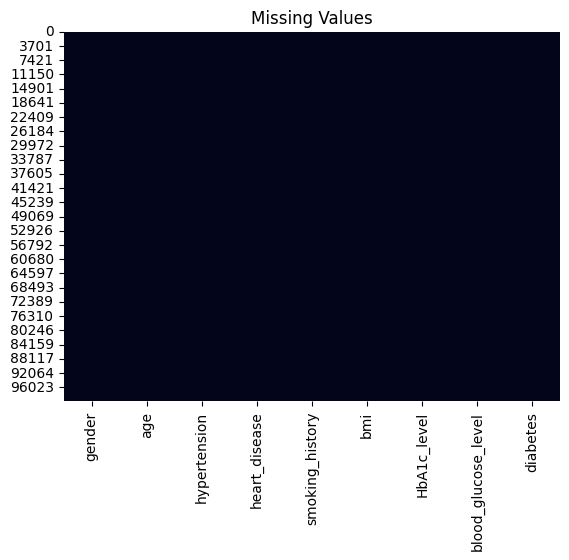

In [ ]:
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

The dataset contains no missing values, so no filling or dropping was required.

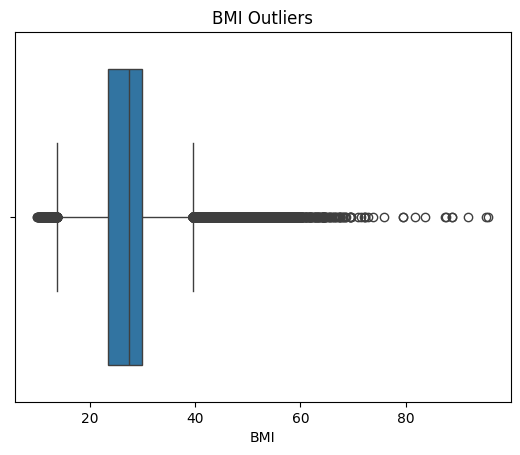

In [ ]:
sns.boxplot(x=df["bmi"])
plt.title("BMI Outliers")
plt.xlabel("BMI")
plt.show()

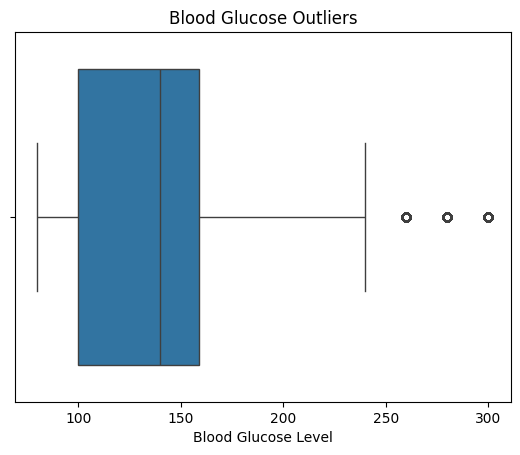

In [ ]:
sns.boxplot(x=df["blood_glucose_level"])
plt.title("Blood Glucose Outliers")
plt.xlabel("Blood Glucose Level")
plt.show()

In [ ]:
q1 = df["bmi"].quantile(0.25)
q3 = df["bmi"].quantile(0.75)

iqr = q3 -q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

outliers = df[(df["bmi"] < lower) | (df["bmi"] > upper)]

print("BMI Outliers:", len(outliers))

BMI Outliers: 5354


In [ ]:
q1 = df["blood_glucose_level"].quantile(0.25)
q3 = df["blood_glucose_level"].quantile(0.75)

iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

outliers = df[(df["blood_glucose_level"] < lower) | (df["blood_glucose_level"] > upper)]

print("Blood Glucose Outliers:", len(outliers))

Blood Glucose Outliers: 2031


In [ ]:
q1 = df["bmi"].quantile(0.25)
q3 = df["bmi"].quantile(0.75)
iqr = q3 - q1

bmi_outliers = df[(df["bmi"] < q1 - 1.5*iqr) | (df["bmi"] > q3 + 1.5*iqr)]

print("BMI Outliers:", len(bmi_outliers))

BMI Outliers: 5354


In [ ]:
q1 = df["blood_glucose_level"].quantile(0.25)
q3 = df["blood_glucose_level"].quantile(0.75)
iqr = q3 - q1

glucose_outliers = df[(df["blood_glucose_level"] < q1 - 1.5*iqr) | (df["blood_glucose_level"] > q3 + 1.5*iqr)]

print("Glucose Outliers:", len(glucose_outliers))

Glucose Outliers: 2031


QUESTIONS

1. Which gender has more patients?
2. Which age group has more patients?
3. What is the distribution of BMI?
4. What is the distribution of HbA1c levels?
5. What is the distribution of blood glucose levels?
6. Is there a relationship between BMI and HbA1c?
7. How are glucose levels related to HbA1c levels?
8. How do glucose levels differ between diabetic and non-diabetic patients?

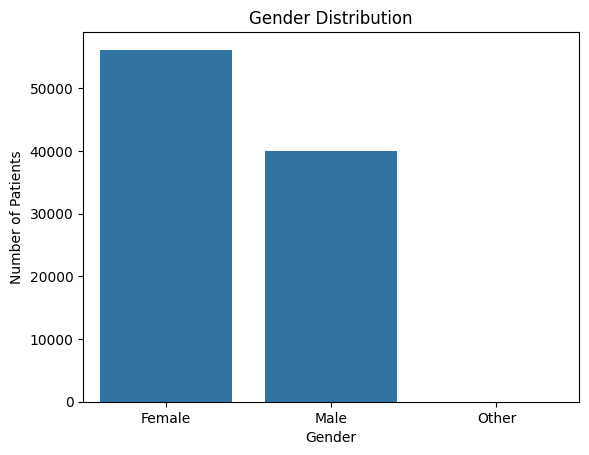

In [ ]:
sns.countplot(x="gender", data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()

This graph shows the number of male and female patients in the dataset.

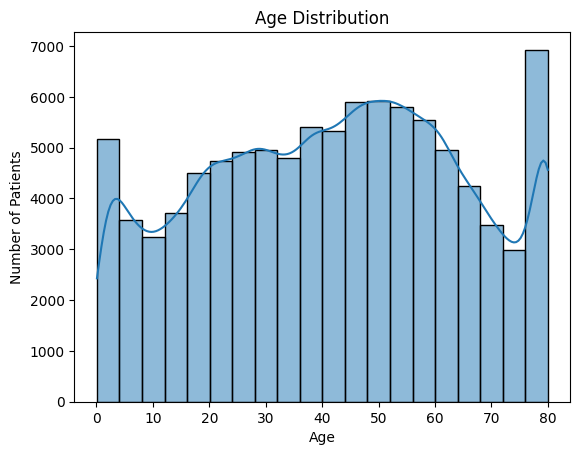

In [ ]:
sns.histplot(df["age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

This histogram shows the age distribution of patients.

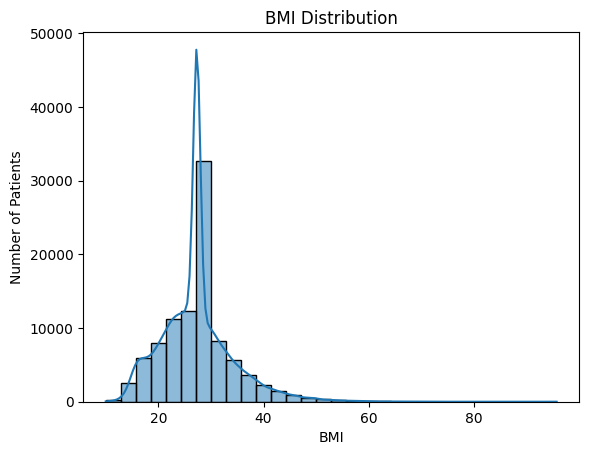

In [ ]:
sns.histplot(df["bmi"], bins=30, kde=True)
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Patients")
plt.show()

This graph shows the distribution of BMI values among patients.

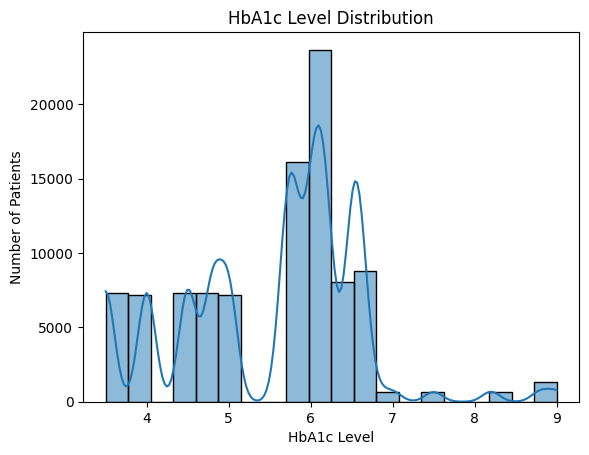

In [ ]:
sns.histplot(df["HbA1c_level"], bins=20, kde=True)
plt.title("HbA1c Level Distribution")
plt.xlabel("HbA1c Level")
plt.ylabel("Number of Patients")
plt.show()

This graph shows the distribution of HbA1c levels among patients.

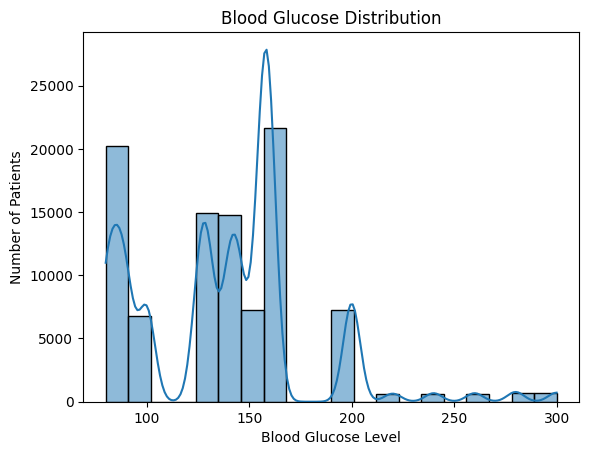

In [ ]:
sns.histplot(df["blood_glucose_level"], bins=20, kde=True)
plt.title("Blood Glucose Distribution")
plt.xlabel("Blood Glucose Level")
plt.ylabel("Number of Patients")
plt.show()

This graph shows the distribution of blood glucose levels among patients.

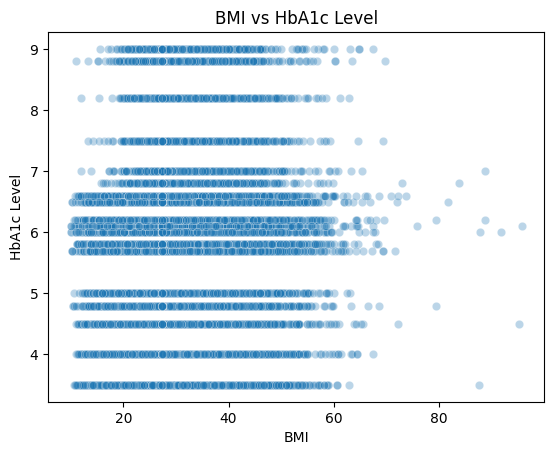

In [ ]:
sns.scatterplot(x="bmi", y="HbA1c_level", data=df, alpha=0.3)
plt.title("BMI vs HbA1c Level")
plt.xlabel("BMI")
plt.ylabel("HbA1c Level")
plt.show()

This scatter plot shows the relationship between BMI and HbA1c levels.

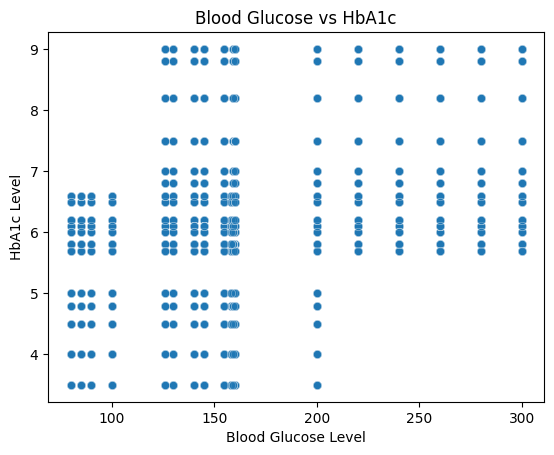

In [ ]:
sns.scatterplot(x="blood_glucose_level", y="HbA1c_level", data=df, alpha=0.3)
plt.title("Blood Glucose vs HbA1c")
plt.xlabel("Blood Glucose Level")
plt.ylabel("HbA1c Level")
plt.show()

This graph shows how blood glucose levels vary with HbA1c levels

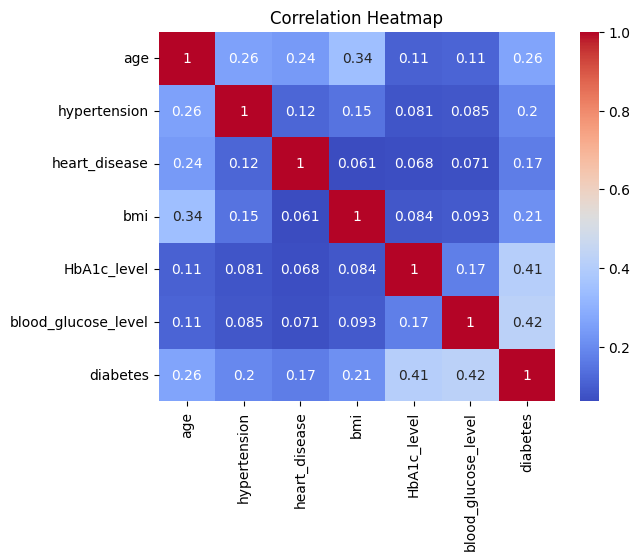

In [ ]:
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

The heatmap shows the correlation between numerical columns in the dataset.

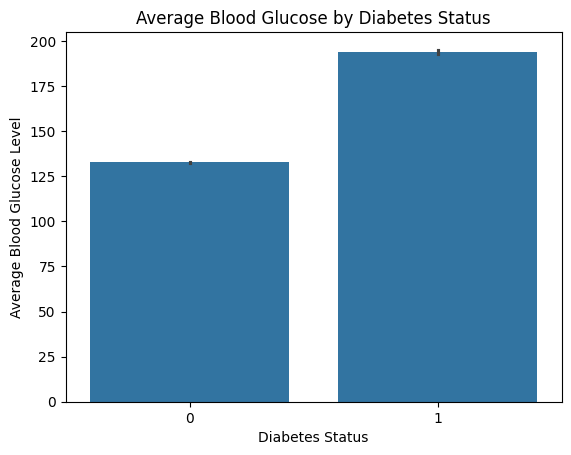

In [ ]:
sns.barplot(x="diabetes", y="blood_glucose_level", data=df)
plt.title("Average Blood Glucose by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Average Blood Glucose Level")
plt.show()

This graph compares average blood glucose levels between diabetic and non-diabetic patients.

In [ ]:
df["gender"].value_counts()

,count
gender,
Female,56161
Male,39967
Other,18


This output shows the number of male and female patients.

In [ ]:
df["age_group"] = pd.cut(df["age"], bins=[0,20,40,60,100])
df["age_group"].value_counts().sort_index()

,count
age_group,
"(0, 20]",20212
"(20, 40]",24832
"(40, 60]",28497
"(60, 100]",22605


This output shows the number of patients in different age groups.

In [ ]:
df[["bmi", "HbA1c_level"]].mean()

,0
bmi,27.321461
HbA1c_level,5.532609


This output shows the average BMI and HbA1c levels of patients.

In [ ]:
df["diabetes"].value_counts()

,count
diabetes,
0,87664
1,8482


This output shows the number of diabetic and non-diabetic patients.

In [ ]:
df.groupby("diabetes")["blood_glucose_level"].mean()

,blood_glucose_level
diabetes,
0,132.818489
1,194.026173


This output compares average blood glucose levels between diabetic and non-diabetic patients.

QUESTIONS | EXISTING GRAPH

1.Gender | Cell 18

2.Age groups | Cell 19 + Cell 28

3.BMI | Cell 20

4.HbA1c | Cell 21

5.Blood glucose | Cell 22

6.BMI vs HbA1c | Cell 23

7.Glucose vs HbA1c | Cell 24

8.Diabetes comparison | Cell 26


##WRITTEN ANSWERS

1. Which gender has more patients?

Female patients are higher in number (56,161) than male patients (39,967).

2. Which age group has more patients?

The 40–60 age group has the highest number of patients, with 28,497 patients.

3. What is the distribution of BMI?

The average BMI is 27.32. Most BMI values are concentrated around the middle range, but some unusually high values are also present.

4. What is the distribution of HbA1c levels?

The average HbA1c level is 5.53, with values ranging from 3.5 to 9.0.

5. What is the distribution of blood glucose levels?

The average blood glucose level is 138.22, with values ranging from 80 to 300.

6. Is BMI related to HbA1c?

BMI and HbA1c have a very weak positive correlation of 0.084. This indicates a very weak relationship.

7. How are glucose levels related to HbA1c?

Blood glucose and HbA1c have a weak positive correlation of 0.172.

8. How do glucose levels differ between diabetic and non-diabetic patients?

Diabetic patients have a higher average blood glucose level (194.03) than non-diabetic patients (132.82).

#CONCLUSIONS

###Key Findings

1.Female patients are higher in number than male patients.

2.The 40–60 age group has the highest number of patients.

3.Diabetic patients have higher average blood glucose and HbA1c levels than non-diabetic patients.

###Actionable Suggestion

Regular blood glucose and HbA1c testing can help identify people who may need further medical assessment and support.